# Histograms and Equalization

A histogram counts how many pixels have each brightness value. It diagnoses exposure problems, drives threshold selection, and - via equalization - fixes flat, low-contrast images. This notebook covers grayscale and colour histograms, masking, equalization, CLAHE and histogram comparison/back-projection ideas.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Calculating and plotting a grayscale histogram

`cv2.calcHist([image], [channel], mask, [bins], [range])` returns the counts. A histogram bunched on the left means a dark image; on the right, an overexposed one; spread out means good contrast.

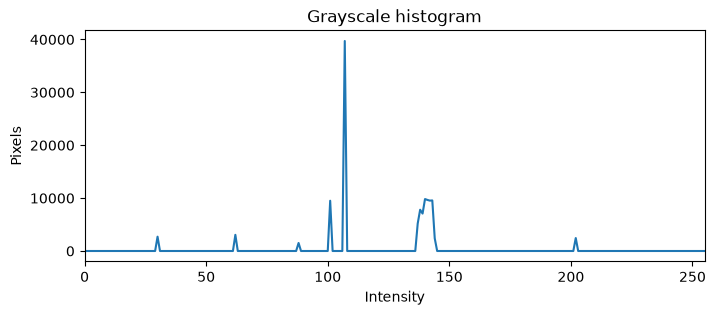

Darkest used intensity: 30 | brightest: 202


In [2]:
gray = cv2.cvtColor(cv2.imread("../assets/test_image.png"), cv2.COLOR_BGR2GRAY)
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
plt.figure(figsize=(8, 3))
plt.plot(hist); plt.xlim(0, 255); plt.title("Grayscale histogram"); plt.xlabel("Intensity"); plt.ylabel("Pixels")
plt.show()
print("Darkest used intensity:", int(np.argmax(hist > 0)), "| brightest:", 255 - int(np.argmax(hist[::-1] > 0)))

## Colour histograms per channel

Computing the histogram separately for B, G and R shows colour casts: if one channel dominates the highlights, the image has a tint of that colour. Plotting all three is the standard white-balance diagnostic.

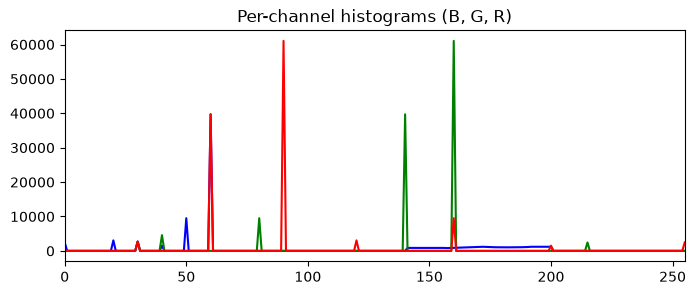

In [3]:
img = cv2.imread("../assets/test_image.png")
plt.figure(figsize=(8, 3))
for i, colour in enumerate(("b", "g", "r")):
    h = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(h, color=colour)
plt.xlim(0, 255); plt.title("Per-channel histograms (B, G, R)"); plt.show()

## Histogram equalization

Equalization stretches the used intensity range across the full 0-255 by redistributing pixels according to the cumulative distribution. It dramatically improves flat, washed-out grayscale images - and destroys already-good ones, so check the histogram first.

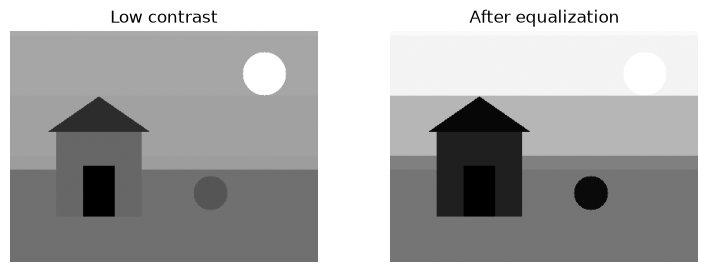

Intensity range before: 80 - 137 | after: 0 - 255


In [4]:
flat = (gray // 3 + 70).astype(np.uint8)   # simulate a low-contrast image
equalized = cv2.equalizeHist(flat)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(flat, cmap="gray"); axes[0].set_title("Low contrast")
axes[1].imshow(equalized, cmap="gray"); axes[1].set_title("After equalization")
for ax in axes: ax.axis("off")
plt.show()
print("Intensity range before:", flat.min(), "-", flat.max(), "| after:", equalized.min(), "-", equalized.max())

## CLAHE - equalization that respects local contrast

Global equalization over-amplifies noise in flat regions. CLAHE equalizes small tiles separately and clips the contrast per tile (clipLimit). It is the standard choice for medical images, documents and faces. For colour, apply it to the L channel of LAB or the V channel of HSV only - never per BGR channel.

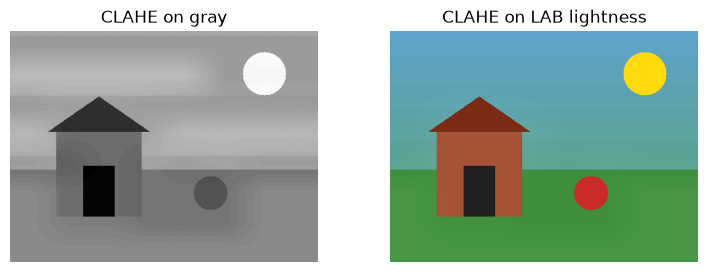

In [5]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_out = clahe.apply(flat)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
colour_fixed = cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(clahe_out, cmap="gray"); axes[0].set_title("CLAHE on gray")
axes[1].imshow(cv2.cvtColor(colour_fixed, cv2.COLOR_BGR2RGB)); axes[1].set_title("CLAHE on LAB lightness")
for ax in axes: ax.axis("off")
plt.show()

## Masked histograms and histogram comparison

A masked histogram describes only a region - the basis of colour-based object description. `cv2.compareHist` scores similarity between two histograms; correlation near 1 means near-identical distributions.

In [6]:
mask = np.zeros(gray.shape, np.uint8)
cv2.circle(mask, (285, 210), 45, 255, -1)
h_region = cv2.calcHist([gray], [0], mask, [256], [0, 256])
h_full = cv2.calcHist([gray], [0], None, [256], [0, 256])
h_other = cv2.calcHist([cv2.cvtColor(cv2.imread("../assets/shapes.png"), cv2.COLOR_BGR2GRAY)], [0], None, [256], [0, 256])
print("Region vs full image correlation:", round(float(cv2.compareHist(h_region, h_full, cv2.HISTCMP_CORREL)), 3))
print("Full vs shapes.png correlation:  ", round(float(cv2.compareHist(h_full, h_other, cv2.HISTCMP_CORREL)), 3))

Region vs full image correlation: 0.815
Full vs shapes.png correlation:   -0.012


## Back projection - finding objects by their histogram

Back projection answers 'where does this colour distribution appear?' Each pixel is replaced by the probability of its intensity under a reference histogram. It powers the CamShift tracker and simple colour-object localisation.

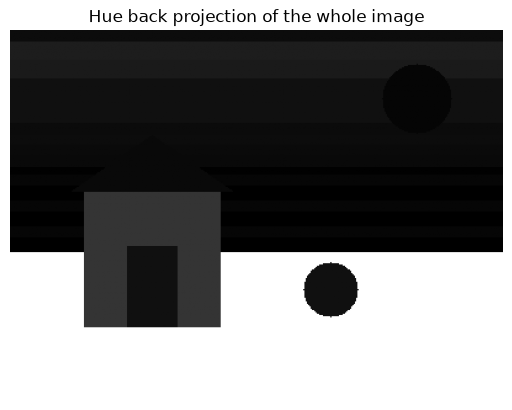

In [7]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
roi_hist = cv2.calcHist([hsv], [0], None, [180], [0, 180])
cv2.normalize(roi_hist, roi_hist, 0, 255, cv2.NORM_MINMAX)
back = cv2.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)
show(back, "Hue back projection of the whole image")

## Key Points

- A histogram shows exposure and contrast at a glance - check it before processing.
- calcHist signature: images, channels, mask, histSize, ranges.
- Equalization stretches contrast globally; it can ruin already-good images.
- CLAHE equalizes locally with clipping - safer for real photos; apply to L or V channel for colour.
- compareHist scores histogram similarity; back projection localises a colour distribution.

## Mini Task

1. Plot the histogram of `noisy_image.png` and state whether it is dark, bright or balanced.
2. Equalize a deliberately darkened copy of `test_image.png` grayscale and print the new intensity range.
3. Compare the histograms of `shapes.png` and `color_blocks.png` with HISTCMP_CORREL and interpret the score.